<a href="https://colab.research.google.com/github/hrhilmane-maker/insdn-openflow-counters/blob/main/insdn-openflow-counters.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd

# 1. Chargement des deux fichiers officiels d'InSDN
normal  = pd.read_csv("/content/Normal_data.csv")
attaque = pd.read_csv("/content/metasploitable-2.csv")
raw = pd.concat([normal, attaque], ignore_index=True)
raw.columns = raw.columns.str.strip()          # enlève les espaces parasites

print("Taille brute :", raw.shape)
print(raw["Label"].value_counts().to_dict())

# 2. Suppression des identifiants
ids = ["Flow ID", "Src IP", "Dst IP", "Src Port", "Dst Port", "Timestamp"]
df = raw.drop(columns=ids)
feats = [c for c in df.columns if c != "Label"]

print("Valeurs manquantes :", int(df[feats].isna().sum().sum()))
print("Valeurs infinies   :", int(np.isinf(df[feats].to_numpy(dtype=float)).sum()))

# 3. Conflits : mêmes attributs, étiquettes différentes
nb_labels = df.groupby(feats, dropna=False)["Label"].nunique()
print("Groupes en conflit :", int((nb_labels > 1).sum()))

# 4. Doublons exacts (attributs + étiquette)
avant = df["Label"].value_counts()
print("Doublons :", int(df.duplicated(subset=feats + ["Label"]).sum()))
df = df.drop_duplicates(subset=feats + ["Label"]).reset_index(drop=True)
apres = df["Label"].value_counts()

# 5. Colonnes constantes (calculées après déduplication)
constantes = [c for c in feats if df[c].nunique() <= 1]
print("Colonnes constantes :", len(constantes), constantes)
df = df.drop(columns=constantes)

print("Taille finale :", df.shape)

# 6. Tableau 1
CLASSES = ["Normal", "Probe", "DDoS", "DoS", "BFA", "U2R"]
tab1 = pd.DataFrame({"Avant": avant, "Après": apres}).reindex(CLASSES)
tab1.loc["Total"] = tab1.sum()
tab1["Supprimés (%)"] = (100 * (1 - tab1["Après"] / tab1["Avant"])).round(1)
print(tab1)

Taille brute : (13155, 84)
{'DDoS': 9072, 'Normal': 3783, 'BFA': 295, 'U2R': 3}
Valeurs manquantes : 124
Valeurs infinies   : 0
Groupes en conflit : 0
Doublons : 8682
Colonnes constantes : 15 ['Fwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'RST Flag Cnt', 'URG Flag Cnt', 'CWE Flag Count', 'ECE Flag Cnt', 'Fwd Byts/b Avg', 'Fwd Pkts/b Avg', 'Fwd Blk Rate Avg', 'Bwd Byts/b Avg', 'Bwd Pkts/b Avg', 'Bwd Blk Rate Avg', 'Init Fwd Win Byts', 'Fwd Seg Size Min']
Taille finale : (4473, 63)
          Avant   Après  Supprimés (%)
Label                                 
Normal   3783.0  3782.0            0.0
Probe       NaN     NaN            NaN
DDoS     9072.0   395.0           95.6
DoS         NaN     NaN            NaN
BFA       295.0   291.0            1.4
U2R         3.0     3.0            0.0
Total   13153.0  4471.0           66.0


In [ ]:
OF6 = ["Flow Duration", "Protocol", "Tot Fwd Pkts", "Tot Bwd Pkts",
       "TotLen Fwd Pkts", "TotLen Bwd Pkts"]

OF14 = OF6 + ["Flow Byts/s", "Flow Pkts/s", "Fwd Pkts/s", "Bwd Pkts/s",
              "Pkt Size Avg", "Fwd Seg Size Avg", "Bwd Seg Size Avg", "Down/Up Ratio"]

ALL = [c for c in df.columns if c != "Label"]

for nom, cols in (("ALL", ALL), ("OF-14", OF14), ("OF-6", OF6)):
    absentes = [c for c in cols if c not in df.columns]
    print(nom, len(cols), "variables | absentes :", absentes)


def audit(cols, nom):
    g = df.groupby(cols, dropna=False)["Label"]
    taille = g.transform("size")          # nb de flux ayant ce vecteur
    nlab   = g.transform("nunique")       # nb d'étiquettes différentes pour ce vecteur

    print(f"\n=== {nom} ===")
    print("Vecteurs distincts            :", g.ngroups)
    print("Flux partageant leur vecteur  :", int((taille > 1).sum()))
    print("Groupes en conflit            :", int((g.nunique() > 1).sum()))
    print("Flux dans un groupe en conflit:", int((nlab > 1).sum()))

    # Par classe : % de flux non uniques et % de flux en conflit
    par_classe = pd.DataFrame({
        "flux": df["Label"].value_counts(),
        "non uniques (%)": (100 * (taille > 1).groupby(df["Label"]).mean()).round(1),
        "en conflit (%)":  (100 * (nlab > 1).groupby(df["Label"]).mean()).round(1),
    }).reindex(CLASSES)
    print(par_classe)

    # Quelles classes se confondent ?
    paires = g.agg(lambda s: " + ".join(sorted(s.unique())))
    paires = paires[g.nunique() > 1].value_counts()
    print("Combinaisons d'étiquettes en conflit :")
    print(paires.to_string())


for nom, cols in (("ALL", ALL), ("OF-14", OF14), ("OF-6", OF6)):
    audit(cols, nom)

# Identifiant de groupe OF-6 (utilisé dans la validation croisée)
df["grp"] = df.groupby(OF6, dropna=False).ngroup()
print("\nNombre de groupes OF-6 :", df["grp"].nunique())

ALL 63 variables | absentes : []
OF-14 14 variables | absentes : []
OF-6 6 variables | absentes : []

=== ALL ===
Vecteurs distincts            : 112304
Flux partageant leur vecteur  : 152
Groupes en conflit            : 76
Flux dans un groupe en conflit: 152
         flux  non uniques (%)  en conflit (%)
Label                                         
Normal  64114              0.0             0.0
Probe   45598              0.2             0.2
DDoS     1495              0.0             0.0
DoS       865              0.1             0.1
BFA       291             25.8            25.8
U2R        17              0.0             0.0
Combinaisons d'étiquettes en conflit :
Label
BFA + Probe    75
DoS + Probe     1

=== OF-14 ===
Vecteurs distincts            : 103021
Flux partageant leur vecteur  : 15706
Groupes en conflit            : 669
Flux dans un groupe en conflit: 1368
         flux  non uniques (%)  en conflit (%)
Label                                         
Normal  64114           

In [ ]:
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import f1_score

SEEDS  = (0, 1, 2)
GROUPS = df["grp"].to_numpy()
y6     = df["Label"].to_numpy()                 # six classes
yb     = (y6 != "Normal").astype(int)           # binaire : 1 = attaque


def predictions_cv(X_train, y, seed, msl=1, X_test=None, grouper=True):
    """Prédictions hors-pli. X_test permet de tester sur d'autres compteurs."""
    X_train = np.asarray(X_train)
    X_test  = X_train if X_test is None else np.asarray(X_test)
    if grouper:
        plis = StratifiedGroupKFold(5, shuffle=True, random_state=seed).split(X_train, y, GROUPS)
    else:
        plis = StratifiedKFold(5, shuffle=True, random_state=seed).split(X_train, y)
    pred = np.empty(len(y), dtype=y.dtype)
    for tr, te in plis:
        m = DecisionTreeClassifier(class_weight="balanced",
                                   min_samples_leaf=msl, random_state=seed)
        m.fit(X_train[tr], y[tr])
        pred[te] = m.predict(X_test[te])
    return pred


def metriques(y, pred):
    """Détection et fausses alarmes, valables en six classes comme en binaire."""
    normal  = "Normal" if y.dtype == object else 0
    attaque = (y != normal)
    alarme  = (pred != normal)
    res = {"detection": 100 * alarme[attaque].mean(),
           "fausses_alarmes": 100 * alarme[~attaque].mean()}
    if y.dtype == object:
        res["macro_F1"] = 100 * f1_score(y, pred, average="macro")
    return res


def resume(liste):
    """Moyenne ± écart-type (ddof=1) sur les graines."""
    r = pd.DataFrame(liste)
    return {k: f"{r[k].mean():.2f} ± {r[k].std(ddof=1):.2f}" for k in r.columns}


# --- Contrôle : aucun groupe OF-6 à la fois en entraînement et en test ---
for tr, te in StratifiedGroupKFold(5, shuffle=True, random_state=0).split(df[OF6], y6, GROUPS):
    assert not set(GROUPS[tr]) & set(GROUPS[te])
    print("pli test :", pd.Series(y6[te]).value_counts().reindex(CLASSES).fillna(0).astype(int).to_dict())


# --- Effet de la fuite sur OF-6 (six classes) ---
for nom, g in (("plis classiques", False), ("plis groupés OF-6", True)):
    res = [metriques(y6, predictions_cv(df[OF6], y6, s, grouper=g)) for s in SEEDS]
    print(f"{nom:18} |", resume(res))

pli test : {'Normal': 12828, 'Probe': 9228, 'DDoS': 293, 'DoS': 176, 'BFA': 68, 'U2R': 2}
pli test : {'Normal': 12865, 'Probe': 9068, 'DDoS': 311, 'DoS': 161, 'BFA': 52, 'U2R': 3}
pli test : {'Normal': 12794, 'Probe': 9066, 'DDoS': 300, 'DoS': 180, 'BFA': 55, 'U2R': 2}
pli test : {'Normal': 12798, 'Probe': 9176, 'DDoS': 297, 'DoS': 172, 'BFA': 61, 'U2R': 6}
pli test : {'Normal': 12829, 'Probe': 9060, 'DDoS': 294, 'DoS': 176, 'BFA': 55, 'U2R': 4}
plis classiques    | {'detection': '98.52 ± 0.02', 'fausses_alarmes': '1.38 ± 0.01', 'macro_F1': '78.31 ± 1.08'}
plis groupés OF-6  | {'detection': '99.32 ± 0.01', 'fausses_alarmes': '1.25 ± 0.01', 'macro_F1': '80.10 ± 1.41'}


In [ ]:
g = df.groupby(OF6, dropna=False)["Label"]
taille = g.transform("size").to_numpy()
nlab   = g.transform("nunique").to_numpy()
statut = np.where(nlab > 1, "en conflit", np.where(taille > 1, "partagé", "unique"))

attaque = (y6 != "Normal")
lignes = []
for nom, grp in (("classiques", False), ("groupés", True)):
    for s in SEEDS:
        alarme = predictions_cv(df[OF6], y6, s, grouper=grp) != "Normal"
        for st in ("unique", "partagé", "en conflit"):
            mN = (~attaque) & (statut == st)
            mA = attaque & (statut == st)
            lignes.append({"plis": nom, "statut": st,
                           "normaux": mN.sum(), "fausses_alarmes": alarme[mN].sum(),
                           "attaques": mA.sum(), "ratées": (~alarme[mA]).sum()})

d = pd.DataFrame(lignes).groupby(["plis", "statut"]).mean()
d["FA (%)"]     = (100 * d["fausses_alarmes"] / d["normaux"]).round(2)
d["ratées (%)"] = (100 * d["ratées"] / d["attaques"]).round(2)
print(d.round(0).astype({"FA (%)": float, "ratées (%)": float}).to_string())

                       normaux  fausses_alarmes  attaques  ratées  FA (%)  ratées (%)
plis       statut                                                                    
classiques en conflit    620.0            581.0     817.0   504.0    94.0        62.0
           partagé      8092.0              2.0    7134.0     0.0     0.0         0.0
           unique      55402.0            299.0   40315.0   208.0     1.0         1.0
groupés    en conflit    620.0            482.0     817.0   140.0    78.0        17.0
           partagé      8092.0             18.0    7134.0     0.0     0.0         0.0
           unique      55402.0            300.0   40315.0   189.0     1.0         0.0


In [ ]:
from sklearn.metrics import recall_score

# --- Tableaux 2 et 3 (plis groupés OF-6) ---
tab2, tab3 = [], {}
for nom, cols in (("ALL", ALL), ("OF-14", OF14), ("OF-6", OF6)):
    runs, recs = [], []
    for s in SEEDS:
        pred = predictions_cv(df[cols], y6, s)
        runs.append(metriques(y6, pred))
        recs.append(recall_score(y6, pred, labels=CLASSES, average=None))
    tab2.append({"jeu": nom, **resume(runs)})
    tab3[nom] = (100 * np.mean(recs, axis=0)).round(1)

print("Tableau 2")
print(pd.DataFrame(tab2).to_string(index=False))
print("\nTableau 3 (rappel par classe, %)")
print(pd.DataFrame(tab3, index=CLASSES).T)


# --- Plancher d'erreur : erreurs inévitables dues aux conflits ---
def plancher(cols, nom):
    ct = pd.crosstab(df.groupby(cols, dropna=False).ngroup(), df["Label"])
    six  = int((ct.sum(axis=1) - ct.max(axis=1)).sum())
    n_norm = ct["Normal"]
    n_att  = ct.drop(columns="Normal").sum(axis=1)
    inevitable = np.minimum(n_norm, n_att)
    print(f"{nom:5} | six classes : {six} erreurs inévitables "
          f"| binaire : {int(inevitable.sum())} "
          f"(soit au moins {100 * inevitable.sum() / len(df):.2f} % des flux)")

print()
plancher(ALL, "ALL")
plancher(OF6, "OF-6")

Tableau 2
  jeu    detection fausses_alarmes     macro_F1
  ALL 99.97 ± 0.01     0.04 ± 0.01 82.01 ± 0.68
OF-14 99.32 ± 0.01     1.24 ± 0.02 78.83 ± 1.43
 OF-6 99.32 ± 0.01     1.25 ± 0.01 80.10 ± 1.41

Tableau 3 (rappel par classe, %)
       Normal  Probe  DDoS   DoS   BFA   U2R
ALL     100.0   99.6  99.6  98.5  34.8  54.9
OF-14    98.8   98.8  99.6  94.8  17.8  60.8
OF-6     98.8   98.8  99.6  95.1  18.1  62.7

ALL   | six classes : 76 erreurs inévitables | binaire : 0 (soit au moins 0.00 % des flux)
OF-6  | six classes : 705 erreurs inévitables | binaire : 597 (soit au moins 0.53 % des flux)


In [ ]:
import pickle

def taille_arbre(X, msl):
    final = DecisionTreeClassifier(class_weight="balanced",
                                   min_samples_leaf=msl, random_state=0).fit(X, yb)
    return final.get_n_leaves(), final.tree_.node_count, len(pickle.dumps(final)) / 1024

tab4 = []
for nom, cols in (("OF-6", OF6), ("ALL", ALL)):
    X = df[cols].to_numpy()
    for msl in (1, 5, 20, 100):
        runs = [metriques(yb, predictions_cv(X, yb, s, msl=msl)) for s in SEEDS]
        feuilles, noeuds, ko = taille_arbre(X, msl)
        tab4.append({"jeu": nom, "min leaf": msl, **resume(runs),
                     "feuilles": feuilles, "nœuds": noeuds, "pickle (Ko)": round(ko)})

print(pd.DataFrame(tab4).to_string(index=False))

 jeu  min leaf    detection fausses_alarmes  feuilles  nœuds  pickle (Ko)
OF-6         1 99.32 ± 0.01     1.21 ± 0.03      1356   2711          213
OF-6         5 99.30 ± 0.02     1.01 ± 0.01       642   1283          101
OF-6        20 99.37 ± 0.05     1.12 ± 0.02       304    607           49
OF-6       100 99.33 ± 0.02     1.61 ± 0.02       122    243           20
 ALL         1 99.97 ± 0.01     0.03 ± 0.00        58    115           10
 ALL         5 99.97 ± 0.00     0.04 ± 0.00        49     97            9
 ALL        20 99.96 ± 0.00     0.07 ± 0.00        38     75            7
 ALL       100 99.89 ± 0.01     0.25 ± 0.00        25     49            5


In [ ]:
# Plis groupés calculés une seule fois par graine, réutilisés partout
PLIS = {s: list(StratifiedGroupKFold(5, shuffle=True, random_state=s)
                .split(np.zeros(len(y6)), y6, GROUPS))
        for s in SEEDS}

def predictions_cv(X_train, y, seed, msl=1, X_test=None, grouper=True):
    X_train = np.asarray(X_train)
    X_test  = X_train if X_test is None else np.asarray(X_test)
    if grouper:
        plis = PLIS[seed]
    else:
        plis = StratifiedKFold(5, shuffle=True, random_state=seed).split(X_train, y)
    pred = np.empty(len(y), dtype=y.dtype)
    for tr, te in plis:
        m = DecisionTreeClassifier(class_weight="balanced",
                                   min_samples_leaf=msl, random_state=seed)
        m.fit(X_train[tr], y[tr])
        pred[te] = m.predict(X_test[te])
    return pred

In [ ]:
X_all = df[ALL].to_numpy()
final = DecisionTreeClassifier(class_weight="balanced",
                               min_samples_leaf=1, random_state=0).fit(X_all, yb)

imp = pd.Series(final.feature_importances_, index=ALL).sort_values(ascending=False)
print("Profondeur :", final.get_depth())
print("Variables utilisées :", int((imp > 0).sum()), "sur", len(ALL))
print(imp[imp > 0].round(3).to_string())

# La variable la plus importante : valeurs typiques par classe
top = imp.index[0]
print(f"\nVariable principale : {top}")
print(df.groupby("Label")[top].describe().reindex(CLASSES).round(1))
print("\nValeurs les plus fréquentes :")
print(pd.crosstab(df[top], df["Label"]).reindex(columns=CLASSES)
        .assign(total=lambda t: t.sum(axis=1))
        .sort_values("total", ascending=False).head(10))

Profondeur : 17
Variables utilisées : 30 sur 63
Pkt Len Max          0.776
Init Bwd Win Byts    0.186
Flow IAT Min         0.013
Active Min           0.010
Fwd Header Len       0.008
SYN Flag Cnt         0.002
Tot Bwd Pkts         0.002
Subflow Fwd Pkts     0.001
Fwd Pkts/s           0.001
Pkt Size Avg         0.001
Bwd Pkt Len Std      0.000
FIN Flag Cnt         0.000
Bwd Pkts/s           0.000
Bwd IAT Mean         0.000
Pkt Len Mean         0.000
Bwd IAT Min          0.000
Pkt Len Var          0.000
Fwd IAT Min          0.000
Bwd Header Len       0.000
Flow IAT Max         0.000
Tot Fwd Pkts         0.000
Idle Mean            0.000
Bwd Pkt Len Mean     0.000
Bwd IAT Tot          0.000
Protocol             0.000
ACK Flag Cnt         0.000
Flow Pkts/s          0.000
Flow Duration        0.000
PSH Flag Cnt         0.000
Down/Up Ratio        0.000

Variable principale : Pkt Len Max
          count    mean     std   min    25%    50%    75%      max
Label                                  

In [ ]:
w = "Init Bwd Win Byts"
print("Valeurs distinctes :", df[w].nunique())
print(pd.crosstab(df[w], df["Label"]).reindex(columns=CLASSES)
        .assign(total=lambda t: t.sum(axis=1))
        .sort_values("total", ascending=False).head(10))

variantes = {
    "ALL":                  ALL,
    "ALL sans fenêtre":     [c for c in ALL if c != w],
    "OF-6":                 OF6,
    "OF-6 + Pkt Len Max":   OF6 + ["Pkt Len Max"],
}
print()
for nom, cols in variantes.items():
    runs = [metriques(yb, predictions_cv(df[cols], yb, s)) for s in SEEDS]
    print(f"{nom:20} |", resume(runs))

Valeurs distinctes : 189
Label              Normal  Probe  DDoS  DoS  BFA  U2R  total
Init Bwd Win Byts                                           
 63                     3  33722     0    0  142    0  33867
-1                  32280      0  1002    0    1    1  33284
 64240              24537      0     0    0    0    0  24537
 215                    6  11503     0  544   98    5  12156
 0                   3674    258     0   53    0    0   3985
 64239               2123      0     0    0    0    0   2123
 5840                   0     16   493    0    0    0    509
 65535                411      0     0    0    0    0    411
 181                    1     73     0  166    2    1    243
 30016                 89      0     0    0    0    0     89

ALL                  | {'detection': '99.97 ± 0.00', 'fausses_alarmes': '0.02 ± 0.00'}
ALL sans fenêtre     | {'detection': '99.95 ± 0.01', 'fausses_alarmes': '0.04 ± 0.00'}
OF-6                 | {'detection': '99.32 ± 0.01', 'fausses_alarme

In [ ]:
taille = df["Pkt Len Max"].to_numpy()
cat = np.select([taille == 0, taille <= 44], ["0 octet", "1–44 octets"], "> 44 octets")

lignes = []
for nom, cols in (("OF-6", OF6), ("ALL", ALL)):
    for s in SEEDS:
        alarme = predictions_cv(df[cols], yb, s) == 1
        for c in ("0 octet", "1–44 octets", "> 44 octets"):
            mN = (yb == 0) & (cat == c)
            mA = (yb == 1) & (cat == c)
            lignes.append({"jeu": nom, "taille max": c,
                           "normaux": mN.sum(), "fausses_alarmes": alarme[mN].sum(),
                           "attaques": mA.sum(), "ratées": (~alarme[mA]).sum()})

d = pd.DataFrame(lignes).groupby(["jeu", "taille max"]).mean()
d["FA (%)"]     = 100 * d["fausses_alarmes"] / d["normaux"]
d["ratées (%)"] = 100 * d["ratées"] / d["attaques"]
print(d.round(2).to_string())

                  normaux  fausses_alarmes  attaques  ratées  FA (%)  ratées (%)
jeu  taille max                                                                 
ALL  0 octet       7123.0            10.67   10996.0    7.00    0.15        0.06
     1–44 octets   2568.0             1.33   37267.0    5.00    0.05        0.01
     > 44 octets  54423.0             4.00       3.0    2.33    0.01       77.78
OF-6 0 octet       7123.0           759.00   10996.0  310.33   10.66        2.82
     1–44 octets   2568.0             6.00   37267.0   14.67    0.23        0.04
     > 44 octets  54423.0             6.00       3.0    2.00    0.01       66.67


In [ ]:
# --- Contrôles ---
print(df["Protocol"].value_counts().to_dict())

vide_compteurs = (df["TotLen Fwd Pkts"] + df["TotLen Bwd Pkts"]) == 0
vide_taille    = df["Pkt Len Max"] == 0
print("Équivalence octets = 0 / taille max = 0 :", bool((vide_compteurs == vide_taille).all()),
      "| flux concernés :", int(vide_compteurs.sum()))

# --- Simulation : on ajoute l'en-tête de chaque paquet ---
HDR = {6: 54, 17: 42, 0: 14}          # TCP, UDP, protocole 0

def vue_switch(d):
    d = d.copy()
    h = d["Protocol"].map(HDR)
    d["TotLen Fwd Pkts"] = d["TotLen Fwd Pkts"] + d["Tot Fwd Pkts"] * h
    d["TotLen Bwd Pkts"] = d["TotLen Bwd Pkts"] + d["Tot Bwd Pkts"] * h
    return d

X  = df[OF6]
Xs = vue_switch(X)
print("Protocoles non reconnus :", int(Xs["TotLen Fwd Pkts"].isna().sum()))

# --- Trois scénarios, plis groupés, min leaf = 20 comme dans l'article ---
tab5 = []
for nom, (a, b) in {"Dataset / dataset":           (X, X),
                    "Dataset / switch":            (X, Xs),
                    "Switch / switch":             (Xs, Xs)}.items():
    runs = [metriques(yb, predictions_cv(a, yb, s, msl=20, X_test=b)) for s in SEEDS]
    tab5.append({"entraînement / test": nom, **resume(runs)})
print(pd.DataFrame(tab5).to_string(index=False))

{6: 79096, 17: 31896, 0: 1388}
Équivalence octets = 0 / taille max = 0 : True | flux concernés : 18119
Protocoles non reconnus : 0
entraînement / test    detection fausses_alarmes
  Dataset / dataset 99.40 ± 0.01     1.14 ± 0.01
   Dataset / switch  2.04 ± 0.00     0.00 ± 0.00
    Switch / switch 99.31 ± 0.01     1.22 ± 0.01


 jeu  min leaf    detection fausses_alarmes  feuilles  nœuds  pickle (Ko)
OF-6         1 99.32 ± 0.01     1.20 ± 0.02      1356   2711          213
OF-6         5 99.29 ± 0.03     1.00 ± 0.03       642   1283          101
OF-6        20 99.40 ± 0.01     1.14 ± 0.01       304    607           49
OF-6       100 99.34 ± 0.08     1.64 ± 0.05       122    243           20
 ALL         1 99.97 ± 0.00     0.02 ± 0.00        58    115           10
 ALL         5 99.97 ± 0.00     0.03 ± 0.00        49     97            9
 ALL        20 99.95 ± 0.01     0.06 ± 0.00        38     75            7
 ALL       100 99.88 ± 0.02     0.26 ± 0.03        25     49            5


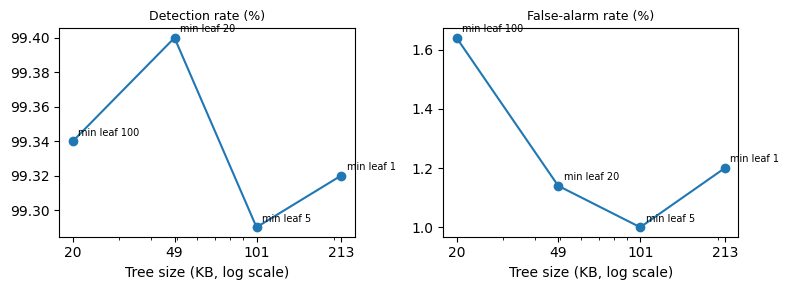

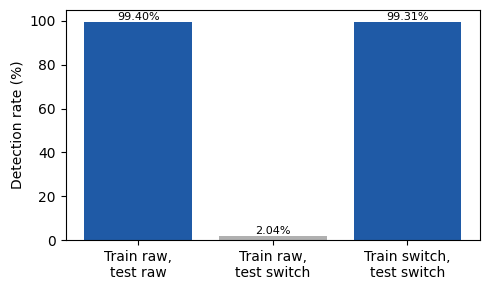

Fichiers enregistrés : ['tableau5_octets.csv', 'tableau1_doublons.csv', 'erreurs_par_taille_paquet.csv', 'fig2_octets.pdf', 'tableau2_six_classes.csv', 'tableau3_rappel.csv', 'tableau4_taille.csv', 'fig1_taille.pdf']


In [ ]:
import os
import matplotlib.pyplot as plt

os.makedirs("resultats", exist_ok=True)
moy = lambda s: float(s.split(" ± ")[0])      # "99.32 ± 0.01" -> 99.32

# --- 1. Tableau 4 avec les plis en cache ---
tab4 = []
for nom, cols in (("OF-6", OF6), ("ALL", ALL)):
    X = df[cols].to_numpy()
    for msl in (1, 5, 20, 100):
        runs = [metriques(yb, predictions_cv(X, yb, s, msl=msl)) for s in SEEDS]
        feuilles, noeuds, ko = taille_arbre(X, msl)
        tab4.append({"jeu": nom, "min leaf": msl, **resume(runs),
                     "feuilles": feuilles, "nœuds": noeuds, "pickle (Ko)": round(ko)})
tab4 = pd.DataFrame(tab4)
print(tab4.to_string(index=False))

# --- 2. Enregistrement de tous les tableaux ---
tab1.to_csv("resultats/tableau1_doublons.csv")
pd.DataFrame(tab2).to_csv("resultats/tableau2_six_classes.csv", index=False)
pd.DataFrame(tab3, index=CLASSES).T.to_csv("resultats/tableau3_rappel.csv")
tab4.to_csv("resultats/tableau4_taille.csv", index=False)
pd.DataFrame(tab5).to_csv("resultats/tableau5_octets.csv", index=False)
d.to_csv("resultats/erreurs_par_taille_paquet.csv")

# --- 3. Figure 1 : détection et fausses alarmes selon la taille (OF-6) ---
f1 = tab4[tab4["jeu"] == "OF-6"]
fig, axes = plt.subplots(1, 2, figsize=(8, 3))
for ax, col, titre in zip(axes, ["detection", "fausses_alarmes"],
                          ["Detection rate (%)", "False-alarm rate (%)"]):
    ax.plot(f1["pickle (Ko)"], f1[col].map(moy), marker="o")
    for _, r in f1.iterrows():
        ax.annotate(f"min leaf {r['min leaf']}", (r["pickle (Ko)"], moy(r[col])),
                    textcoords="offset points", xytext=(4, 4), fontsize=7)
    ax.set_xscale("log")
    ax.set_xticks(f1["pickle (Ko)"]); ax.set_xticklabels(f1["pickle (Ko)"])
    ax.set_xlabel("Tree size (KB, log scale)"); ax.set_title(titre, fontsize=9)
plt.tight_layout(); plt.savefig("resultats/fig1_taille.pdf"); plt.show()

# --- 4. Figure 2 : les trois scénarios de comptage des octets ---
f2 = pd.DataFrame(tab5)
vals = f2["detection"].map(moy)
fig, ax = plt.subplots(figsize=(5, 3))
barres = ax.bar(["Train raw,\ntest raw", "Train raw,\ntest switch", "Train switch,\ntest switch"],
                vals, color=["#1f5aa6", "#b0b0b0", "#1f5aa6"])
ax.bar_label(barres, labels=[f"{v:.2f}%" for v in vals], fontsize=8)
ax.set_ylabel("Detection rate (%)"); ax.set_ylim(0, 105)
plt.tight_layout(); plt.savefig("resultats/fig2_octets.pdf"); plt.show()

print("Fichiers enregistrés :", os.listdir("resultats"))

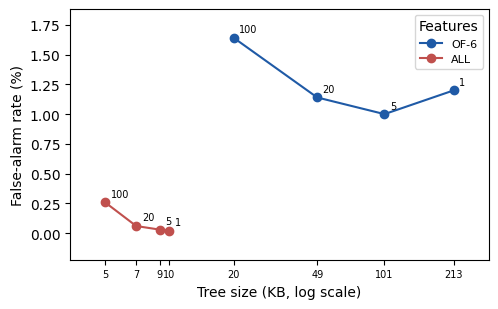

In [ ]:
f1 = tab4.copy()
f1["FA"] = f1["fausses_alarmes"].map(moy)

fig, ax = plt.subplots(figsize=(5, 3.2))
for nom, couleur in (("OF-6", "#1f5aa6"), ("ALL", "#c0504d")):
    t = f1[f1["jeu"] == nom]
    ax.plot(t["pickle (Ko)"], t["FA"], marker="o", color=couleur, label=nom)
    for _, r in t.iterrows():
        ax.annotate(f"{r['min leaf']}", (r["pickle (Ko)"], r["FA"]),
                    textcoords="offset points", xytext=(4, 4), fontsize=7)
ax.set_xscale("log")
tailles = sorted(f1["pickle (Ko)"].unique())
ax.set_xticks(tailles); ax.set_xticklabels(tailles, fontsize=7)
ax.minorticks_off()
ax.set_xlabel("Tree size (KB, log scale)")
ax.set_ylabel("False-alarm rate (%)")
ax.legend(title="Features", fontsize=8)
ax.margins(x=0.1, y=0.15)
plt.tight_layout(); plt.savefig("resultats/fig1_taille.pdf"); plt.show()